Région 1 : animal (confiance 0.93), boîte (282, 456, 375, 546), 5501 px
Région 2 : animal (confiance 0.69), boîte (1026, 487, 1182, 609), 11068 px
Région 3 : obstacle (confiance 0.86), boîte (860, 525, 899, 592), 1948 px
Classe annoncée pour l'image : animal


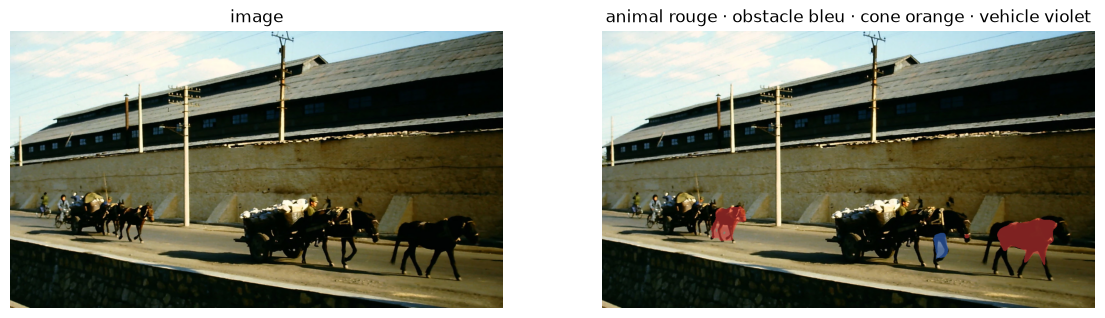

In [7]:
import numpy as np, torch, matplotlib.pyplot as plt
from PIL import Image
import bo2_mobilenet_commun as C

IMAGE = r"C:\Users\nour\Desktop\DEEP\RoadAnomaly\RoadAnomaly\frames\vehicle03_Fuhrwerke_in_China.webp"   # <- chemin de ton image 
SEUIL_LOC = 0.25                            # seuil du U-Net choisi sur la validation
REJET = 0.5                                 # en dessous : « objet inconnu »

# 1. Les deux modèles : U-Net du BO1 (localise) + ton MobileNetV2 (classe)
loc, _ = C.load_loc_unet(C.os.path.join(C.ROOT, "outputs_unet_resnet34_pretrained", "unet_resnet34_pretrained_best.pt"))
clf = C.build_mobilenet(pretrained=False)
ck = torch.load(C.os.path.join(C.ROOT, "outputs_bo2_mobilenetv2_pretrained", "bo2_mobilenetv2_pretrained_best.pt"),
                map_location=C.DEVICE, weights_only=False)
clf.load_state_dict(ck["state_dict"]); clf = clf.to(C.DEVICE).eval()

# 2. L'image seule : pas de masque, pas de nom utilisé
img = np.array(Image.open(IMAGE).convert("RGB"))
cache = {"upload": (img, np.zeros(img.shape[:2], np.uint8))}

# 3. Chaîne complète : U-Net -> régions -> MobileNetV2
probs = C.unet_probs(loc, ["upload"], cache)
maps, info = C.pipeline_maps(probs, clf, ["upload"], cache, SEUIL_LOC, return_regions=True)

# 4. Résultat
regions = info["upload"]
if not regions:
    print("Aucune anomalie détectée.")
for i, r in enumerate(regions, 1):
    k, conf = int(r["probs"].argmax()), float(r["probs"].max())
    nom = C.OBJ_CLASSES[k] if conf >= REJET else "objet inconnu"
    print(f"Région {i} : {nom} (confiance {conf:.2f}), boîte {r['bbox']}, {r['area']} px")
k_img = C.image_decision(maps["upload"])
print("Classe annoncée pour l'image :", C.CLASSES[k_img] if k_img else "rien")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].imshow(img); ax[0].set_title("image")
ax[1].imshow(C.overlay(img, maps["upload"])); ax[1].set_title("animal rouge · obstacle bleu · cone orange · vehicle violet")
for a in ax: a.axis("off")
plt.show()
